---
title: "Practice Activity 10-1: Model Selection and Hyperparameter Tuning"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    code-overflow: wrap
---

# Model Selection and Hyperparameter Tuning

**Use scikit-learn as much as possible!**

In [1]:
import pandas as pd
import numpy as np

## Ames Housing Data

As usual, we'll try to predict SalePrice using a mix of quantitative and categorical features. See the [data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for all the variables that are available in the data set. We'll try to come up with a model that minimizes test error, measured by root mean square error (RMSE).

In [2]:
df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

y = df_ames["SalePrice"]
folds = KFold(n_splits=5, shuffle=True, random_state=5544)

1\. Recall that in a previous notebook we fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. But what about other sets of features?

Specify 5 sets of features to investigate. These sets could be subsets of the variables above, but you should also include other variables from the data set. The choice is up to you, but try to guess which sets might lead to good models based on your intuition and what we have already seen for this data set.

For each set of features, fit a 10-nearest neighbors regression model and estimate its test error (RMSE) using cross-validation. You can write a loop to iterate over the sets of features similar to what was done in the Model Selection section of the pre-class notebook.

Report your lowest RMSE and the corresponding features.

In [4]:
feature_sets = {
    "Original": (
        ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"],
        ["Neighborhood"]
    ),
    "Size + quality": (
        ["Gr Liv Area", "Overall Qual"],
        []
    ),
    "Size + quality + year": (
        ["Gr Liv Area", "Overall Qual", "Year Built"],
        []
    ),
    "Add neighborhood": (
        ["Gr Liv Area", "Overall Qual", "Year Built"],
        ["Neighborhood"]
    ),
    "Add garage": (
        ["Gr Liv Area", "Overall Qual", "Year Built", "Garage Area"],
        ["Neighborhood"]
    )
}

In [5]:
results = {}

for name, (numeric, categorical) in feature_sets.items():
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])

    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical)
    ])

    model = Pipeline([
        ("preprocessing", preprocessing),
        ("knn", KNeighborsRegressor(n_neighbors=10))
    ])

    scores = cross_val_score(
        model,
        df_ames[numeric + categorical],
        y,
        cv=folds,
        scoring="neg_root_mean_squared_error"
    )

    results[name] = -scores.mean()

q1_results = pd.Series(results, name="CV RMSE").sort_values()
q1_results

Add garage               32209.988021
Add neighborhood         32979.635930
Size + quality + year    33508.880775
Size + quality           36548.851850
Original                 39260.779926
Name: CV RMSE, dtype: float64

**Answer:** Among the five feature sets, the lowest estimated test RMSE was 32209.99 dollars using Gr Liv Area, Overall Qual, Year Built, Garage Area, and Neighborhood. All models used 10-nearest neighbors and the same five cross-validation folds. Adding Garage Area reduced the estimated test RMSE from 32979.64 to 32209.99 dollars compared with the feature set without it.

2\. Recall that in a previous notebook we fit a $k$-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Previously we used a loop to iterate and find the value of $k$ with the smallest test error (RMSE).

Now use grid search in scikit-learn to implement this process. Use the results to create a plot of test error versus $k$.

In [6]:
numeric_q2, categorical_q2 = feature_sets["Original"]
X_q2 = df_ames[numeric_q2 + categorical_q2]

preprocessing_q2 = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_q2),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_q2)
])

pipeline_q2 = Pipeline([
    ("preprocessing", preprocessing_q2),
    ("knn", KNeighborsRegressor())
])

grid_q2 = GridSearchCV(
    pipeline_q2,
    param_grid={"knn__n_neighbors": range(1, 26)},
    cv=folds,
    scoring="neg_root_mean_squared_error"
)

grid_q2.fit(X_q2, y)

print("Best k:", grid_q2.best_params_["knn__n_neighbors"])
print("Best CV RMSE:", -grid_q2.best_score_)

Best k: 6
Best CV RMSE: 38980.41873746954


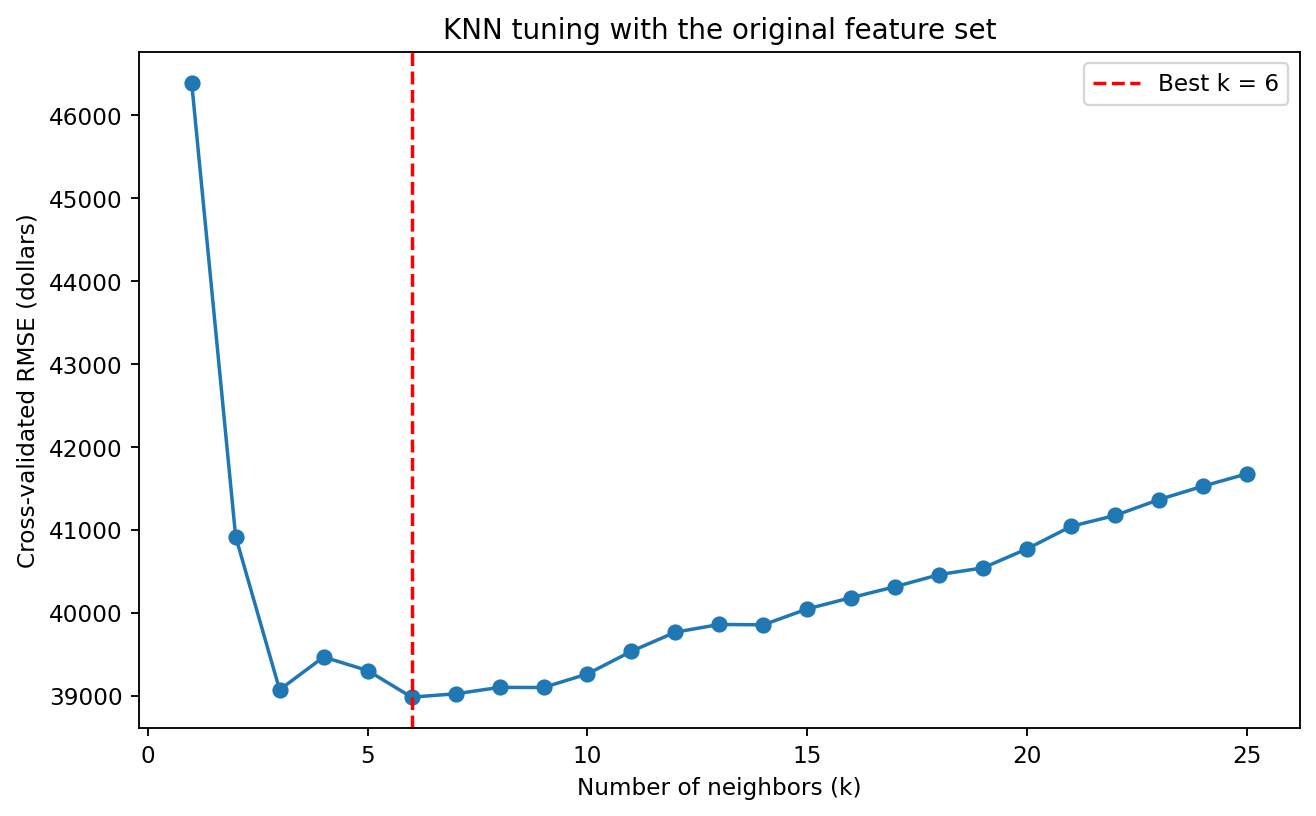

In [7]:
import matplotlib.pyplot as plt

q2_results = pd.DataFrame(grid_q2.cv_results_)
q2_results["CV RMSE"] = -q2_results["mean_test_score"]
best_k_q2 = grid_q2.best_params_["knn__n_neighbors"]

plt.figure(figsize=(8, 5))
plt.plot(q2_results["param_knn__n_neighbors"], q2_results["CV RMSE"], marker="o")
plt.axvline(best_k_q2, color="red", linestyle="--", label=f"Best k = {best_k_q2}")
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Cross-validated RMSE (dollars)")
plt.title("KNN tuning with the original feature set")
plt.legend()
plt.tight_layout()
plt.show()

**Answer:** Using the five specified features, grid search over k values from 1 to 25 selected k = 6, with an estimated test RMSE of 38980.42 dollars from five-fold cross-validation. The plot shows that RMSE decreases sharply at first, reaches its minimum at k = 6, and generally increases for larger k. Several nearby values have similar errors.

3\. $k$-nearest neighbors relies on distance and we know there are different distance metrics. Repeat the previous part and use grid search to iterate over both (1) `n_neighbors` and (2) `metric`, which can be `"euclidean"` or `"manhattan"` (see the the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)). Compare the results to the previous part. (Hint: recall the note in the pre-class notebook about grid search conventions for refering to steps in the pipeline.)

In [8]:
grid_q3 = GridSearchCV(
    pipeline_q2,
    param_grid={
        "knn__n_neighbors": range(1, 26),
        "knn__metric": ["euclidean", "manhattan"]
    },
    cv=folds,
    scoring="neg_root_mean_squared_error"
)

grid_q3.fit(X_q2, y)

print("Best parameters:", grid_q3.best_params_)
print("Best CV RMSE:", -grid_q3.best_score_)
print("RMSE reduction from Question 2:", grid_q3.best_score_ - grid_q2.best_score_)

Best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 6}
Best CV RMSE: 38643.48775566348
RMSE reduction from Question 2: 336.9309818060574


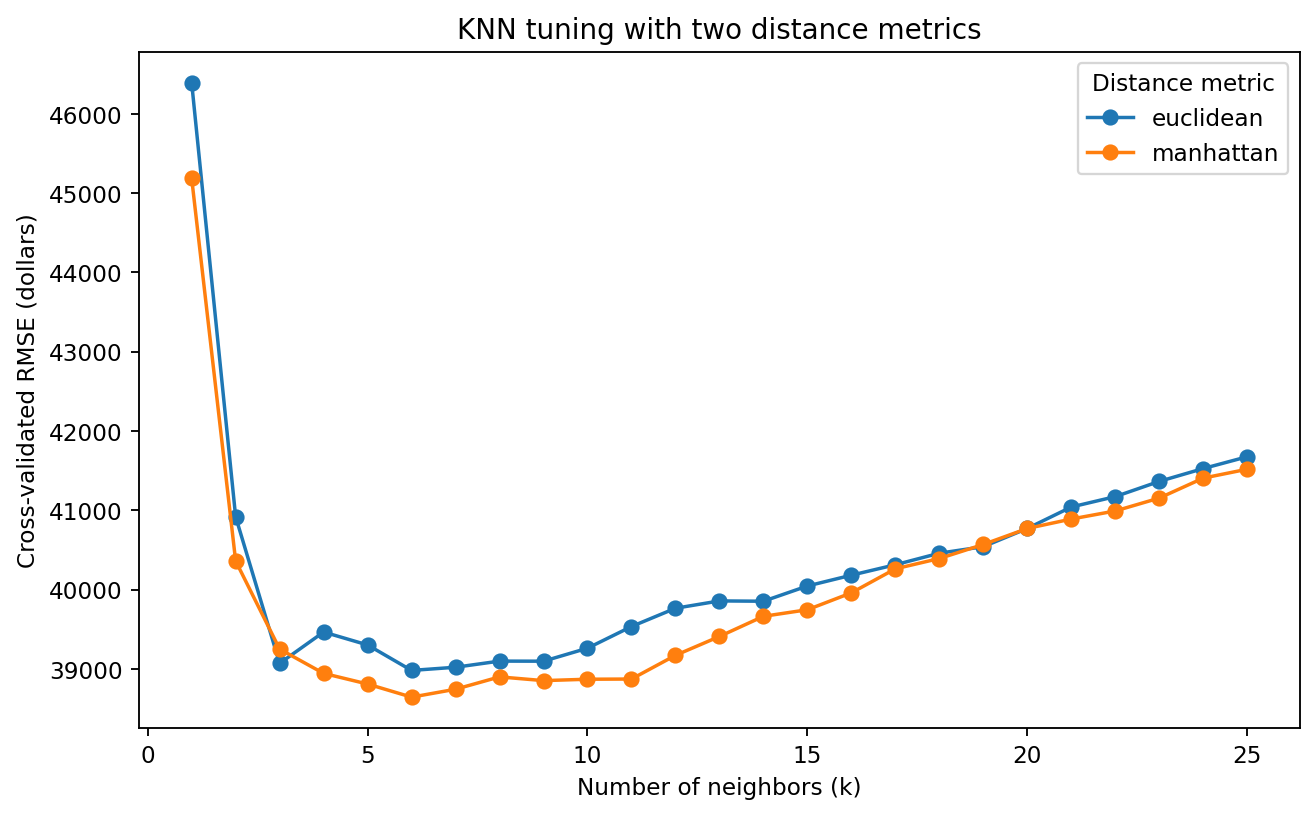

In [9]:
q3_results = pd.DataFrame(grid_q3.cv_results_)
q3_results["CV RMSE"] = -q3_results["mean_test_score"]

q3_plot = q3_results.pivot(
    index="param_knn__n_neighbors",
    columns="param_knn__metric",
    values="CV RMSE"
)

q3_plot.plot(figsize=(8, 5), marker="o")
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Cross-validated RMSE (dollars)")
plt.title("KNN tuning with two distance metrics")
plt.legend(title="Distance metric")
plt.tight_layout()
plt.show()

**Answer:** Using the same five features and cross-validation folds as in Question 2, grid search over k values from 1 to 25 and both distance metrics selected k = 6 with Manhattan distance. The estimated test RMSE was 38643.49 dollars, compared with 38980.42 dollars using Euclidean distance in Question 2. This is a modest reduction of 336.93 dollars. The plot shows similar overall patterns for both metrics, with Manhattan distance producing slightly lower errors for most k values.

4\. Combine elements of the previous parts and fit what you think will be the best $k$-nearest neighbors model. Specify which features you are using, the value of $k$, and the distance metric. Estimate the test error. (In 2-3 you used the specified set of features. Now you can combine elements of 2-3 with the features you chose in part 1, or other sets of features, as well as investigating other parameter choices.)

Note: Look at the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) for a full list of parameters. You might consider tuning `n_neighbors`, `metric` (or `p`), and/or `weights`. You could also try other elements like scaling too.

In [10]:
numeric_q4, categorical_q4 = feature_sets["Add garage"]
X_q4 = df_ames[numeric_q4 + categorical_q4]

preprocessing_q4 = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_q4),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_q4)
])

pipeline_q4 = Pipeline([
    ("preprocessing", preprocessing_q4),
    ("knn", KNeighborsRegressor())
])

grid_q4 = GridSearchCV(
    pipeline_q4,
    param_grid={
        "knn__n_neighbors": range(1, 26),
        "knn__metric": ["euclidean", "manhattan"],
        "knn__weights": ["uniform", "distance"]
    },
    cv=folds,
    scoring="neg_root_mean_squared_error"
)

grid_q4.fit(X_q4, y)
best_knn = grid_q4.best_estimator_

print("Features:", numeric_q4 + categorical_q4)
print("Best parameters:", grid_q4.best_params_)
print("Best CV RMSE:", -grid_q4.best_score_)

Features: ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Garage Area', 'Neighborhood']
Best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 6, 'knn__weights': 'distance'}
Best CV RMSE: 30101.39879128232


**Answer:** My selected KNN model uses Gr Liv Area, Overall Qual, Year Built, Garage Area, and Neighborhood. Grid search over k values from 1 to 25, Euclidean and Manhattan distances, and uniform and distance weights selected k = 6 with Manhattan distance and distance weighting. Its estimated test RMSE from five-fold cross-validation was 30101.40 dollars, the lowest among the KNN models I tried. This improves on the RMSE of 32209.99 dollars obtained with the same features and the default settings at k = 10 in Question 1.

5\. Now fit a linear regression model using the same features that you used in the previous part. Estimate the test error. How does the test error for linear regression compare to the kNN model?


In [11]:
pipeline_q5 = Pipeline([
    ("preprocessing", preprocessing_q4),
    ("linear_regression", LinearRegression())
])

scores_q5 = cross_val_score(
    pipeline_q5,
    X_q4,
    y,
    cv=folds,
    scoring="neg_root_mean_squared_error"
)

rmse_q5 = -scores_q5.mean()

comparison_q5 = pd.Series({
    "Tuned KNN": -grid_q4.best_score_,
    "Linear regression": rmse_q5
}, name="CV RMSE").sort_values()

comparison_q5

Tuned KNN            30101.398791
Linear regression    34779.266710
Name: CV RMSE, dtype: float64

**Answer:** Using the same five features and cross-validation folds as in Question 4, linear regression had an estimated test RMSE of 34779.27 dollars. The tuned KNN model had a lower RMSE of 30101.40 dollars, a difference of 4677.87 dollars. I would therefore prefer the tuned KNN model for prediction based on this comparison.

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

Note: when you are consider features to include, you might want to consider transformations of the variables.

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [12]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


In [13]:
df.info()

df["interest_rate"].describe()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 56 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Unnamed: 0                        10000 non-null  int64  
 1   emp_title                         9167 non-null   str    
 2   emp_length                        9183 non-null   float64
 3   state                             10000 non-null  str    
 4   homeownership                     10000 non-null  str    
 5   annual_income                     10000 non-null  float64
 6   verified_income                   10000 non-null  str    
 7   debt_to_income                    9976 non-null   float64
 8   annual_income_joint               1495 non-null   float64
 9   verification_income_joint         1455 non-null   str    
 10  debt_to_income_joint              1495 non-null   float64
 11  delinq_2y                         10000 non-null  int64  
 12  months_since_las

count    10000.000000
mean        12.427524
std          5.001105
min          5.310000
25%          9.430000
50%         11.980000
75%         15.050000
max         30.940000
Name: interest_rate, dtype: float64

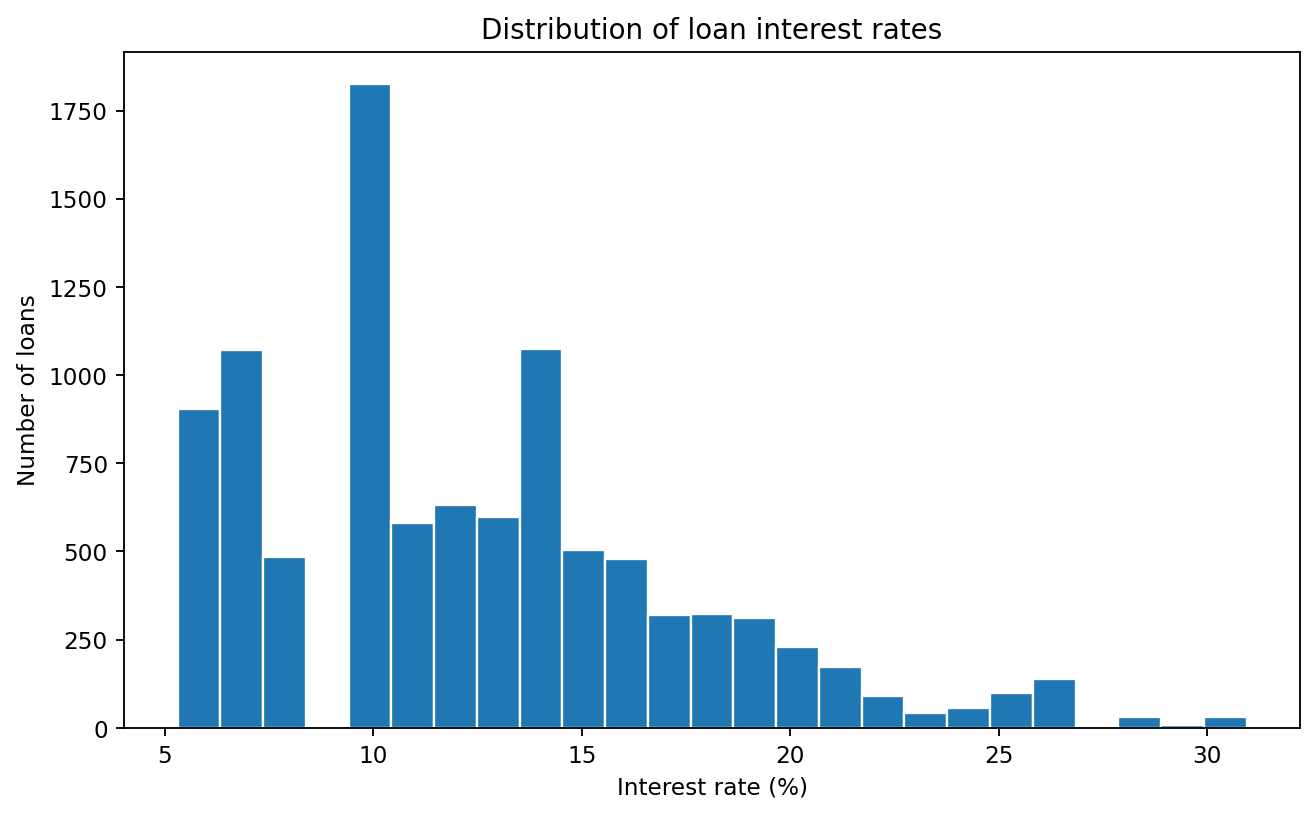

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["interest_rate"], bins=25, edgecolor="white")
plt.xlabel("Interest rate (%)")
plt.ylabel("Number of loans")
plt.title("Distribution of loan interest rates")
plt.tight_layout()
plt.show()

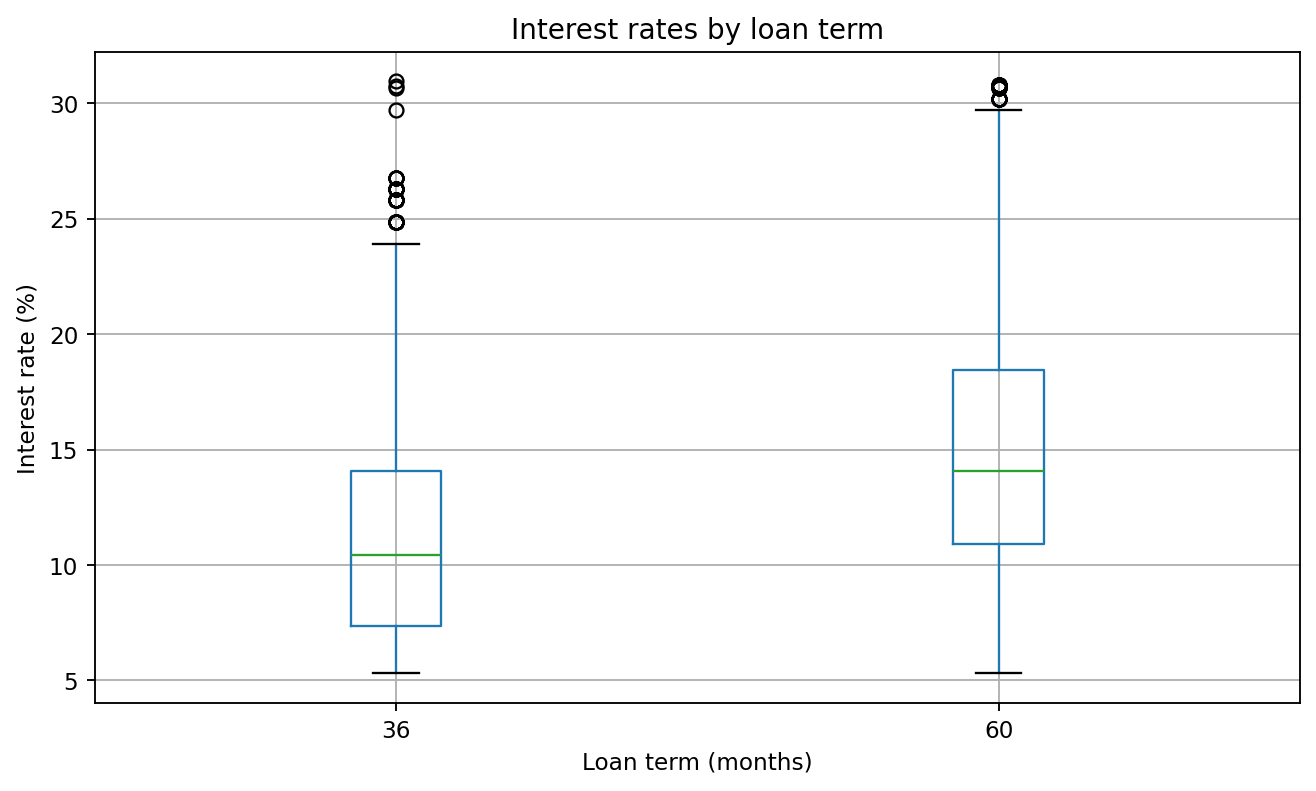

In [15]:
df.boxplot(column="interest_rate", by="term", figsize=(8, 5))
plt.xlabel("Loan term (months)")
plt.ylabel("Interest rate (%)")
plt.title("Interest rates by loan term")
plt.suptitle("")
plt.tight_layout()
plt.show()

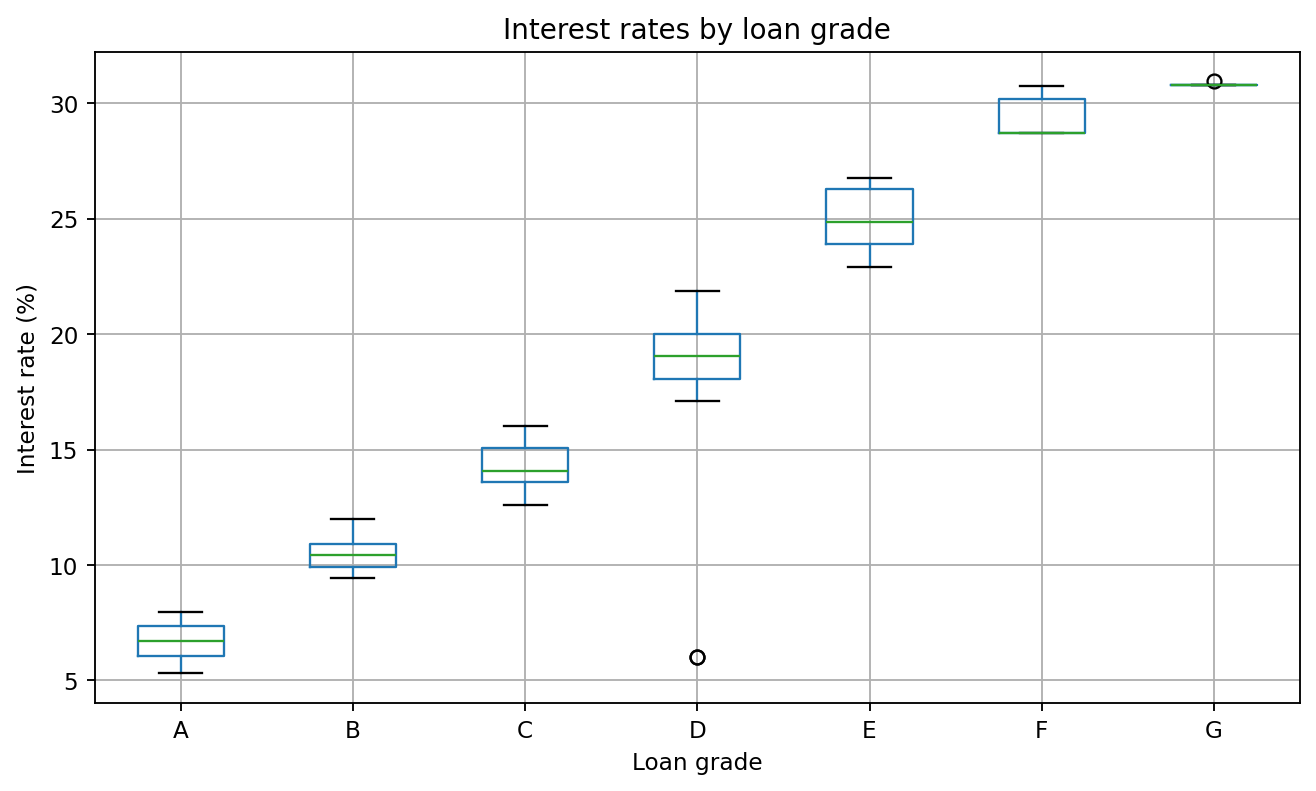

In [16]:
df.boxplot(column="interest_rate", by="grade", figsize=(8, 5))
plt.xlabel("Loan grade")
plt.ylabel("Interest rate (%)")
plt.title("Interest rates by loan grade")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Answer:** The dataset contains 10000 loans, with no missing values in interest_rate. The mean interest rate is 12.43%, the median is 11.98%, and the standard deviation is about 5.00 percentage points. The distribution is right-skewed. Loans with a 60-month term generally have higher interest rates than those with a 36-month term, although their distributions overlap. Interest rates also increase clearly across grades from A to G, suggesting that grade may be useful for prediction. These patterns show associations, not causal effects. For models using grade, I assume it is known at prediction time. The data represent loans actually made, rather than all loan applications.

In [17]:
loan_numeric = ["annual_income", "debt_to_income", "loan_amount", "term"]
loan_categorical = ["homeownership", "loan_purpose"]

X_loans = df[loan_numeric + loan_categorical]
y_loans = df["interest_rate"]
loan_folds = KFold(n_splits=5, shuffle=True, random_state=5544)

loan_preprocessing = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), loan_numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), loan_categorical)
])

loan_lr = Pipeline([
    ("preprocessing", loan_preprocessing),
    ("linear_regression", LinearRegression())
])

loan_lr_scores = cross_val_score(
    loan_lr,
    X_loans,
    y_loans,
    cv=loan_folds,
    scoring="neg_root_mean_squared_error"
)

loan_lr_rmse = -loan_lr_scores.mean()

print("Linear regression CV RMSE:", loan_lr_rmse)

Linear regression CV RMSE: 4.538729364722213


In [18]:
loan_grade_categorical = loan_categorical + ["grade"]
X_loans_grade = df[loan_numeric + loan_grade_categorical]

loan_grade_preprocessing = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), loan_numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), loan_grade_categorical)
])

loan_grade_lr = Pipeline([
    ("preprocessing", loan_grade_preprocessing),
    ("linear_regression", LinearRegression())
])

loan_grade_scores = cross_val_score(
    loan_grade_lr,
    X_loans_grade,
    y_loans,
    cv=loan_folds,
    scoring="neg_root_mean_squared_error"
)

loan_grade_rmse = -loan_grade_scores.mean()

pd.Series({
    "Linear regression without grade": loan_lr_rmse,
    "Linear regression with grade": loan_grade_rmse
}, name="CV RMSE").sort_values()

Linear regression with grade       1.104434
Linear regression without grade    4.538729
Name: CV RMSE, dtype: float64

In [19]:
subgrade_summary = df.groupby("sub_grade")["interest_rate"].agg(
    ["count", "mean", "std", "min", "max"]
)

subgrade_summary.round(3)

,count,mean,std,min,max
sub_grade,,,,,
A1,422,5.316,0.005,5.31,5.32
A2,480,6.076,0.006,6.00,6.08
A3,504,6.716,0.005,6.71,6.72
A4,568,7.346,0.005,7.34,7.35
A5,485,7.966,0.005,7.96,7.97
B1,647,9.436,0.005,9.43,9.44
B2,638,9.926,0.005,9.92,9.93
B3,540,10.416,0.005,10.41,10.42
B4,581,10.905,0.005,10.90,10.91


In [20]:
loan_subgrade_categorical = loan_categorical + ["sub_grade"]
X_loans_subgrade = df[loan_numeric + loan_subgrade_categorical]

loan_subgrade_preprocessing = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), loan_numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), loan_subgrade_categorical)
])

loan_subgrade_lr = Pipeline([
    ("preprocessing", loan_subgrade_preprocessing),
    ("linear_regression", LinearRegression())
])

loan_subgrade_scores = cross_val_score(
    loan_subgrade_lr,
    X_loans_subgrade,
    y_loans,
    cv=loan_folds,
    scoring="neg_root_mean_squared_error"
)

loan_subgrade_rmse = -loan_subgrade_scores.mean()

pd.Series({
    "Without grade": loan_lr_rmse,
    "With grade": loan_grade_rmse,
    "With sub_grade": loan_subgrade_rmse
}, name="Linear regression CV RMSE").sort_values()

With sub_grade    0.191144
With grade        1.104434
Without grade     4.538729
Name: Linear regression CV RMSE, dtype: float64

In [21]:
from sklearn.tree import DecisionTreeRegressor

loan_tree_preprocessing = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), loan_numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), loan_subgrade_categorical)
])

loan_tree = Pipeline([
    ("preprocessing", loan_tree_preprocessing),
    ("tree", DecisionTreeRegressor(random_state=5544))
])

loan_tree_grid = GridSearchCV(
    loan_tree,
    param_grid={
        "tree__max_depth": [5, 10, 20, None],
        "tree__min_samples_leaf": [1, 5, 20]
    },
    cv=loan_folds,
    scoring="neg_root_mean_squared_error"
)

loan_tree_grid.fit(X_loans_subgrade, y_loans)

print("Best tree parameters:", loan_tree_grid.best_params_)
print("Tree CV RMSE:", -loan_tree_grid.best_score_)
print("Linear regression CV RMSE:", loan_subgrade_rmse)

Best tree parameters: {'tree__max_depth': None, 'tree__min_samples_leaf': 1}
Tree CV RMSE: 0.2770384205564754
Linear regression CV RMSE: 0.19114387808547656


In [22]:
loan_model_comparison = pd.Series({
    "Linear regression without grade": loan_lr_rmse,
    "Linear regression with grade": loan_grade_rmse,
    "Linear regression with sub_grade": loan_subgrade_rmse,
    "Tuned regression tree with sub_grade": -loan_tree_grid.best_score_
}, name="CV RMSE (percentage points)").sort_values()

best_loan_model = loan_subgrade_lr.fit(X_loans_subgrade, y_loans)

loan_model_comparison

Linear regression with sub_grade        0.191144
Tuned regression tree with sub_grade    0.277038
Linear regression with grade            1.104434
Linear regression without grade         4.538729
Name: CV RMSE (percentage points), dtype: float64

**Answer:** I compared linear regression models without loan grades, with grade, and with sub_grade, as well as a regression tree tuned using GridSearchCV. All models used the same five cross-validation folds. The lowest estimated test RMSE was 0.1911 percentage points, achieved by linear regression using annual_income, debt_to_income, loan_amount, term, homeownership, loan_purpose, and sub_grade. The best regression tree used max_depth=None and min_samples_leaf=1, with a higher RMSE of 0.2770 percentage points. I selected the linear regression model and refitted it on all 10000 loans. Its strong performance relies on sub_grade being available at prediction time. Some subgrades have very few observations, so predictions for those groups are less certain.